# 07 — Quality control, statistics and masks

**Goal:** before interpreting values, check that they are valid: no-data, the product `mask`
layer, the number of looks, outliers, and the statistics of each polarization, overall and per
land unit (clear-cut and control forest).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "07"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "frequency", "aoi_window"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])
from nisar_s1.polarimetry import to_db
from nisar_s1.grid import polygon_mask
from nisar_s1.optical import Raster
import geopandas as gpd

In [2]:
with src_ctx() as h5:
    prof = P.product_profile(h5)
    grid = prof.grids[session["frequency"]]
    win = P.window_from_bounds(grid, session["aoi_bounds"])
    L = {t: P.read_layer(h5, grid, t, win) for t in grid.terms}
    mask = P.read_layer(h5, grid, "mask", win, nodata_zero=False)
    looks = P.read_layer(h5, grid, "numberOfLooks", win)
vals, counts = np.unique(mask, return_counts=True)
print("mask values in the AOI:", dict(zip(vals.tolist(), counts.tolist())))

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5
mask values in the AOI: {1: 89856}


The `mask` layer of NISAR L2 products encodes, per pixel, which sub-swath(s) imaged it; **0 means
no valid sub-swath** and **255 is the fill value** outside the swath. Any other value is a valid pixel.

In [3]:
valid = (mask != 0) & (mask != 255)
qc = []
for t, a in L.items():
    fin = np.isfinite(a)
    qc.append({"term": t, "valid by mask (%)": 100 * valid.mean(), "finite (%)": 100 * fin.mean(),
               "finite but masked": int((fin & ~valid).sum()), "<= 0": int((a <= 0).sum()),
               "median looks": float(np.nanmedian(looks))})
pd.DataFrame(qc).round(2)

,term,valid by mask (%),finite (%),finite but masked,<= 0,median looks
0,HHHH,100.0,100.0,0,0,10.61
1,HVHV,100.0,100.0,0,0,10.61


## Statistics and outliers (dB)

In [4]:
rows = []
for t, a in L.items():
    db = to_db(a)[valid & np.isfinite(a)]
    q1, q3 = np.percentile(db, [25, 75])
    out = ((db < q1 - 3 * (q3 - q1)) | (db > q3 + 3 * (q3 - q1))).mean() * 100
    rows.append({"term": t, "mean": db.mean(), "median": np.median(db), "std": db.std(),
                 "p2": np.percentile(db, 2), "p98": np.percentile(db, 98), "outliers 3·IQR (%)": out})
stats = pd.DataFrame(rows).round(2); stats

,term,mean,median,std,p2,p98,outliers 3·IQR (%)
0,HHHH,-6.17,-5.57,3.31,-14.090000,-0.75,0.06
1,HVHV,-11.39,-10.62,3.45,-19.639999,-6.10,0.00


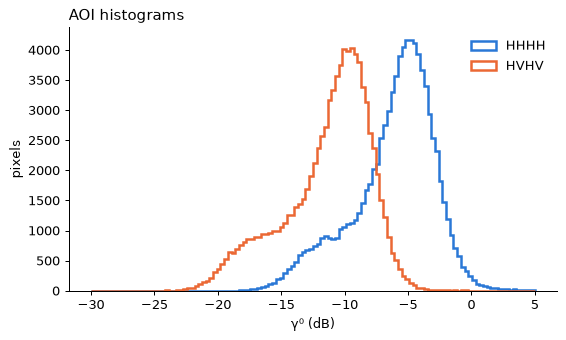

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for t, c in zip(L, ["#2a78d6", "#eb6834"]):
    ax.hist(to_db(L[t])[valid].ravel(), bins=120, range=(-30, 5), histtype="step", lw=2, color=c, label=t)
ax.set_xlabel("γ⁰ (dB)"); ax.set_ylabel("pixels"); ax.legend(frameon=False)
ax.set_title("AOI histograms", loc="left"); plt.show()

## Statistics per land unit
The scene is from 3 November 2026, **after** the clear-cut (July–August). At L-band the cut should
show a lower HV (less volume scattering) than the surrounding forest. Polygons are eroded by one
pixel to avoid mixed edge pixels.

In [6]:
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(grid.epsg)
ref = Raster(np.zeros(win.shape, "float32"), win.transform, win.crs)
unit = []
for _, s in sites.iterrows():
    m = polygon_mask([s.geometry], ref, erode_m=abs(grid.dx)) & valid
    unit.append({"unit": s.role, "pixels": int(m.sum()),
                 **{f"{t} median (dB)": float(np.nanmedian(to_db(L[t])[m])) for t in L}})
units = pd.DataFrame(unit).round(2); units

,unit,pixels,HHHH median (dB),HVHV median (dB)
0,cut,25,-8.26,-13.58
1,control,238,-4.72,-9.20


In [7]:
P.save_session(kit["session_file"], qc_valid_fraction=float(valid.mean()))
np.save(OUT / "valid_mask.npy", valid)

In [8]:
checks = {
    "AOI mostly valid (> 95 %)": valid.mean() > 0.95,
    "no non-positive powers": all(r['<= 0'] == 0 for r in qc),
    "cut darker than control in HV": units.set_index("unit").loc["cut", "HVHV median (dB)"] < units.set_index("unit").loc["control", "HVHV median (dB)"],
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 07 STATUS: PASS")

  [x] AOI mostly valid (> 95 %)
  [x] no non-positive powers
  [x] cut darker than control in HV
Module 07 STATUS: PASS
